# 01 — Protocol repair and honest baselines

This notebook does the unglamorous but necessary part of the ZoomMoE plan:
rebuild the BreaKHis pipeline with **patient-disjoint** folds, then re-measure
the existing conditional-fusion baseline on data it has never seen.

What it produces:

1. A parsed dataframe with the **correct patient identifier** (the original
   notebook used `parts[1]`, the year field, which is not a patient id).
2. Multi-scale samples that keep incomplete magnification groups instead of
   dropping ~22% of the data.
3. Patient-disjoint 5-fold CV with an audited no-leak guarantee.
4. Four baselines: single-scale 40x, single-scale 400x, feature concat, and a
   faithful PyTorch port of the Keras conditional-fusion model.
5. A side-by-side of the **leaky protocol vs the honest protocol**, so the gap
   between the reported 96.09% and reality is measured rather than guessed.

Everything downstream (notebooks 02 and 03) reuses the folds built here.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models

# breakhis_common.py must be importable: put it beside this notebook, or add it
# as a Kaggle utility script / dataset.
COMMON_DIR = "/kaggle/input/datasets/nabinkoirala452/code-files-mc"

if COMMON_DIR not in sys.path:
    sys.path.insert(0, COMMON_DIR)

import breakhis_common as bc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
IMG_SIZE = 224
NUM_CLASSES = bc.N_CLASSES
CLASS_NAMES = list(bc.CLASS_NAMES)
OUT = Path("artifacts")
OUT.mkdir(exist_ok=True)

bc.set_seed(SEED)
print("device:", DEVICE, "| torch:", torch.__version__)
print("classes:", dict(enumerate(CLASS_NAMES)))

device: cuda | torch: 2.10.0+cu128
classes: {0: 'Adenosis', 1: 'Fibroadenoma', 2: 'Phyllodes Tumor', 3: 'Tubular Adenoma', 4: 'Ductal Carcinoma', 5: 'Lobular Carcinoma', 6: 'Mucinous Carcinoma', 7: 'Papillary Carcinoma'}


## 1. Scan the dataset

The filename `SOB_B_TA-14-4659-40-001.png` decomposes as
`biopsy_class_subtype - year - slide - magnification - image`.
The patient (biopsy) is the whole prefix `SOB_B_TA-14-4659`, which is what
folds must be grouped by. The subtype codes are mapped to eight classes:
Adenosis, Fibroadenoma, Phyllodes Tumor, Tubular Adenoma, Ductal Carcinoma,
Lobular Carcinoma, Mucinous Carcinoma, and Papillary Carcinoma.

In [2]:
ROOT = bc.find_dataset_root()
print("dataset root:", ROOT)

df = bc.scan_breakhis(ROOT)
bc.dataset_summary(df)
df.head()

dataset root: /kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1
images            : 7909
patients (biopsies): 82
patients by class  :
  0: Adenosis             4
  1: Fibroadenoma         10
  2: Phyllodes Tumor      3
  3: Tubular Adenoma      7
  4: Ductal Carcinoma     38
  5: Lobular Carcinoma    5
  6: Mucinous Carcinoma   9
  7: Papillary Carcinoma  6
tumour subtypes    : ['A', 'DC', 'F', 'LC', 'MC', 'PC', 'PT', 'TA']

images per magnification / class:
label    0    1    2    3    4    5    6    7
mag                                          
40     114  253  109  149  864  156  205  145
100    113  260  121  150  903  170  222  142
200    111  264  108  140  896  163  196  135
400    106  237  115  130  788  137  169  138


,filepath,label,tumor_type,patient_id,mag,image_id
0,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,12
1,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,9
2,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,6
3,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,11
4,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,4


### Class and patient checks

The scan should report eight subtype classes. The full biopsy prefix is used
as the patient identifier so no patient can cross a fold boundary.

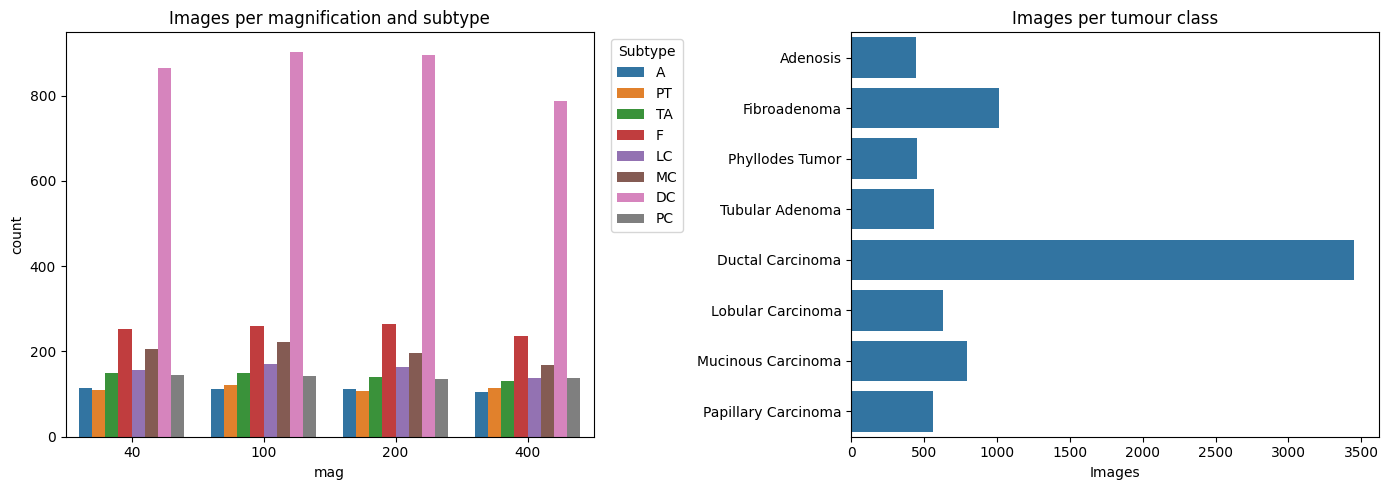

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="mag", hue="tumor_type", ax=ax[0])
ax[0].set_title("Images per magnification and subtype")
ax[0].legend(title="Subtype", bbox_to_anchor=(1.02, 1), loc="upper left")
summary = df.assign(class_name=df["label"].map(dict(enumerate(CLASS_NAMES))))
sns.countplot(data=summary, y="class_name", order=CLASS_NAMES, ax=ax[1])
ax[1].set_title("Images per tumour class")
ax[1].set_xlabel("Images")
ax[1].set_ylabel("")
plt.tight_layout()
plt.savefig(OUT / "fig_distribution.png", dpi=150)
plt.show()

## 2. Group into multi-scale samples

Two grouping modes, both kept so the effect can be ablated later:

* `image_id` — reproduces the baseline pairing (image 001 at 40x with image
  001 at 400x). Convenient, but those are **not** the same field of view.
* `pool` — candidates for each magnification are every image of that patient
  at that magnification, and one is drawn at random per epoch. This is honest
  about the lack of registration and doubles as augmentation.

In [4]:
samples_full = bc.build_groups(df, pair_mode="image_id", drop_incomplete=True)
samples_all = bc.build_groups(df, pair_mode="image_id", drop_incomplete=False)
samples_pool = bc.build_groups(df, pair_mode="pool", drop_incomplete=False)

print(f"complete 4-magnification groups only : {len(samples_full)}  (baseline used this)")
print(f"all groups, variable length          : {len(samples_all)}")
print("magnifications available per sample:")
print(samples_all.n_mags.value_counts().sort_index())

complete 4-magnification groups only : 1558  (baseline used this)
all groups, variable length          : 2407
magnifications available per sample:
n_mags
1     314
2     242
3     293
4    1558
Name: count, dtype: int64


## 3. Patient-disjoint folds

`audit_folds` asserts that no patient id appears in two splits of the same
fold. If this cell raises, stop and fix it before running anything else.

In [5]:
folds = bc.make_folds(samples_all, n_splits=5, val_frac=0.15, seed=SEED)
bc.audit_folds(samples_all, folds)

# folds over the complete-groups subset, for like-for-like baseline comparison
folds_full = bc.make_folds(samples_full, n_splits=5, val_frac=0.15, seed=SEED)
bc.audit_folds(samples_full, folds_full)

np.save(OUT / "folds_all.npy", np.array(folds, dtype=object), allow_pickle=True)
np.save(OUT / "folds_full.npy", np.array(folds_full, dtype=object), allow_pickle=True)
samples_all.to_pickle(OUT / "samples_all.pkl")
samples_full.to_pickle(OUT / "samples_full.pkl")
samples_pool.to_pickle(OUT / "samples_pool.pkl")
print("saved folds and sample tables to", OUT)

fold 0: n={'train': 1559, 'val': 324, 'test': 524}  patients={'train': 56, 'val': 10, 'test': 16}  class counts={'train': [88, 226, 17, 70, 777, 146, 190, 45], 'val': [32, 32, 42, 37, 47, 0, 42, 92], 'test': [0, 60, 66, 56, 248, 55, 22, 17]}
fold 1: n={'train': 1616, 'val': 287, 'test': 504}  patients={'train': 56, 'val': 10, 'test': 16}  class counts={'train': [88, 230, 59, 148, 725, 146, 175, 45], 'val': [32, 32, 66, 15, 49, 0, 22, 71], 'test': [0, 56, 0, 0, 298, 55, 57, 38]}
fold 2: n={'train': 1703, 'val': 228, 'test': 476}  patients={'train': 55, 'val': 10, 'test': 17}  class counts={'train': [52, 200, 66, 110, 839, 179, 184, 73], 'val': [36, 37, 17, 16, 37, 22, 27, 36], 'test': [32, 81, 42, 37, 196, 0, 43, 45]}
fold 3: n={'train': 1625, 'val': 302, 'test': 480}  patients={'train': 56, 'val': 10, 'test': 16}  class counts={'train': [17, 179, 108, 95, 824, 145, 212, 45], 'val': [32, 18, 0, 37, 99, 0, 42, 74], 'test': [71, 121, 17, 31, 149, 56, 0, 35]}
fold 4: n={'train': 1701, 'val

## 4. Precompute frozen VGG16 features

Every baseline here uses a frozen encoder, so the features are computed once
and cached. This makes the whole baseline sweep run in seconds instead of
hours. Notebook 02 works from raw pixels because ZoomMoE fine-tunes.

In [6]:
@torch.no_grad()
def precompute_vgg_features(paths, batch_size=64, img_size=224):
    from PIL import Image

    tf = bc.build_transforms(img_size, train=False)
    vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
    vgg = vgg.eval().to(DEVICE)

    cache, buf, keys = {}, [], []

    def flush():
        if not buf:
            return
        x = torch.stack(buf).to(DEVICE)
        f = vgg(x).mean(dim=(2, 3))  # global average pool -> 512-d
        for k, v in zip(keys, f.cpu().numpy().astype(np.float32)):
            cache[k] = v
        buf.clear()
        keys.clear()

    t0 = time.time()
    for i, p in enumerate(paths):
        buf.append(tf(Image.open(p).convert("RGB")))
        keys.append(p)
        if len(buf) == batch_size:
            flush()
        if i % 2000 == 0:
            print(f"  {i}/{len(paths)}  ({time.time() - t0:.0f}s)", flush=True)
    flush()
    vgg.cpu()
    torch.cuda.empty_cache()
    return cache


cache_path = OUT / "vgg16_features.npz"
if cache_path.exists():
    z = np.load(cache_path)
    feat_cache = {k: z[k] for k in z.files}
    print("loaded cached features:", len(feat_cache))
else:
    feat_cache = precompute_vgg_features(df.filepath.tolist())
    np.savez_compressed(cache_path, **feat_cache)
    print("computed and cached features:", len(feat_cache))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 230MB/s]


  0/7909  (0s)
  2000/7909  (52s)
  4000/7909  (104s)
  6000/7909  (156s)
computed and cached features: 7909


## 5. Baseline models

`ConditionalFusion` is a faithful port of the Keras baseline: magnification
embedding concatenated to each 512-d feature, a dense projection to 256, one
4-head self-attention layer over the four tokens with a residual, mean pool,
128-d embedding, and an eight-class softmax head. The only additions are a
padding mask so incomplete samples are handled, and an exposed `embedding` for
t-SNE.

In [7]:
class SingleScale(nn.Module):
    """Baseline: one magnification only."""

    def __init__(self, mag_index, feat_dim=512, hid=256, n_classes=NUM_CLASSES):
        super().__init__()
        self.mag_index = mag_index
        self.net = nn.Sequential(
            nn.Linear(feat_dim, hid), nn.ReLU(), nn.Dropout(0.3), nn.Linear(hid, n_classes)
        )

    def forward(self, feats, mask):
        return self.net(feats[:, self.mag_index])


class ConcatMLP(nn.Module):
    """Baseline: concatenate all four magnifications, zeros where missing."""

    def __init__(self, feat_dim=512, n_mags=4, hid=512, n_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feat_dim * n_mags, hid), nn.ReLU(), nn.Dropout(0.4), nn.Linear(hid, n_classes)
        )

    def forward(self, feats, mask):
        x = feats * mask.unsqueeze(-1).float()
        return self.net(x.flatten(1))


class ConditionalFusion(nn.Module):
    """PyTorch port of the Keras multi-head conditional fusion baseline."""

    def __init__(self, feat_dim=512, n_mags=4, mag_dim=32, hid=256, heads=4, emb=128, n_classes=NUM_CLASSES):
        super().__init__()
        self.mag_emb = nn.Embedding(n_mags, mag_dim)
        self.proj = nn.Sequential(nn.Linear(feat_dim + mag_dim, hid), nn.ReLU(), nn.Dropout(0.30))
        self.attn = nn.MultiheadAttention(hid, heads, batch_first=True)
        self.embed = nn.Sequential(nn.Linear(hid, emb), nn.ReLU(), nn.Dropout(0.40))
        self.head = nn.Linear(emb, n_classes)
        self.register_buffer("mag_ids", torch.arange(n_mags))

    def forward(self, feats, mask, return_embedding=False):
        B, M, _ = feats.shape
        e = self.mag_emb(self.mag_ids).unsqueeze(0).expand(B, -1, -1)
        tokens = self.proj(torch.cat([feats, e], dim=-1))

        pad = ~mask
        # a fully padded row would produce NaNs; keep at least one valid slot
        pad = pad & ~(pad.all(dim=1, keepdim=True))
        a, _ = self.attn(tokens, tokens, tokens, key_padding_mask=pad)
        fused = tokens + a

        w = mask.unsqueeze(-1).float()
        pooled = (fused * w).sum(1) / w.sum(1).clamp(min=1.0)
        z = self.embed(pooled)
        logits = self.head(z)
        return (logits, z) if return_embedding else logits


print(
    "params  single:",
    bc.count_params(SingleScale(0)),
    "| concat:",
    bc.count_params(ConcatMLP()),
    "| fusion:",
    bc.count_params(ConditionalFusion()),
)

params  single: 133384 | concat: 1053192 | fusion: 436744


## 6. Train / evaluate loop

Model selection on the validation fold by AUC; the test fold is scored once,
with the best validation checkpoint. No prediction is ever made on data the
model trained on.

In [8]:
def run_epoch(model, loader, optimiser=None):
    train = optimiser is not None
    model.train(train)
    losses, probs, ys, pids = [], [], [], []

    for batch in loader:
        feats = batch["feats"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        y = batch["label"].to(DEVICE)

        with torch.set_grad_enabled(train):
            logits = model(feats, mask)
            loss = F.cross_entropy(logits, y)

        if train:
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()

        losses.append(loss.item())
        probs.append(torch.softmax(logits, dim=-1).detach().cpu().numpy())
        ys.append(y.cpu().numpy())
        pids.append(batch["patient_idx"].numpy())

    return (
        float(np.mean(losses)),
        np.concatenate(probs),
        np.concatenate(ys),
        np.concatenate(pids),
    )


def run_baseline(model_fn, samples, folds, epochs=30, lr=1e-3, batch_size=64, tag=""):
    rows = []
    for fi, fold in enumerate(folds):
        bc.set_seed(SEED + fi)
        loaders = {
            k: DataLoader(
                bc.make_feature_dataset(samples.iloc[fold[k]], feat_cache),
                batch_size=batch_size,
                shuffle=(k == "train"),
                num_workers=2,
            )
            for k in ("train", "val", "test")
        }

        model = model_fn().to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=lr)

        best_auc = -1.0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        for ep in range(epochs):
            run_epoch(model, loaders["train"], opt)
            _, vp, vy, vpid = run_epoch(model, loaders["val"])
            vm = bc.evaluate(vy, vp, vpid)
            current_auc = vm.get("auc", 0.0)
            if current_auc is not None and not np.isnan(current_auc) and current_auc > best_auc:
                best_auc = current_auc
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        model.load_state_dict(best_state)
        _, tp, ty, tpid = run_epoch(model, loaders["test"])
        m = bc.evaluate(ty, tp, tpid)
        m["fold"] = fi
        rows.append(m)
        print(f"  [{tag}] fold {fi}: " + "  ".join(f"{k}={v:.4f}" for k, v in m.items() if k != "fold"))

    return rows

## 7. Run the baselines (honest protocol)

In [9]:
EPOCHS = 30
results = {}

configs = {
    "single_40x": lambda: SingleScale(0),
    "single_400x": lambda: SingleScale(3),
    "concat_4scale": lambda: ConcatMLP(),
    "conditional_fusion": lambda: ConditionalFusion(),
}

for name, fn in configs.items():
    print(f"\n=== {name} (patient-disjoint, {NUM_CLASSES}-class) ===")
    results[name] = run_baseline(fn, samples_full, folds_full, epochs=EPOCHS, tag=name)

table = pd.DataFrame(
    {
        name: bc.summarise_folds(rows).apply(
            lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1
        )
        for name, rows in results.items()
    }
).T
table = table[["acc", "prr", "f1_macro", "auc"]]
table.columns = ["Image Acc", "Patient RR", "Macro-F1", "ROC-AUC (OVR)"]
display(table)
table.to_csv(OUT / "baseline_results_honest_multiclass.csv")


=== single_40x (patient-disjoint, 8-class) ===
  [single_40x] fold 0: acc=0.3368  f1_macro=0.2160  prr=0.3343  auc=0.8394
  [single_40x] fold 1: acc=0.4598  f1_macro=0.1464  prr=0.4956  auc=0.7059
  [single_40x] fold 2: acc=0.3314  f1_macro=0.1421  prr=0.3868  auc=0.7636
  [single_40x] fold 3: acc=0.4813  f1_macro=0.1814  prr=0.5105  auc=0.7805
  [single_40x] fold 4: acc=0.7566  f1_macro=0.3507  prr=0.7047  auc=0.8357

=== single_400x (patient-disjoint, 8-class) ===
  [single_400x] fold 0: acc=0.4016  f1_macro=0.1943  prr=0.3747  auc=0.7736
  [single_400x] fold 1: acc=0.5125  f1_macro=0.1285  prr=0.5383  auc=0.6983
  [single_400x] fold 2: acc=0.3692  f1_macro=0.1578  prr=0.4240  auc=0.7099
  [single_400x] fold 3: acc=0.4689  f1_macro=0.2391  prr=0.4604  auc=0.7720
  [single_400x] fold 4: acc=0.6460  f1_macro=0.1942  prr=0.5869  auc=0.5798

=== concat_4scale (patient-disjoint, 8-class) ===
  [concat_4scale] fold 0: acc=0.4689  f1_macro=0.3962  prr=0.4750  auc=0.8814
  [concat_4scale] f

,Image Acc,Patient RR,Macro-F1,ROC-AUC (OVR)
single_40x,0.4732 ± 0.1727,0.4864 ± 0.1426,0.2074 ± 0.0855,0.7850 ± 0.0554
single_400x,0.4796 ± 0.1086,0.4769 ± 0.0857,0.1828 ± 0.0418,0.7067 ± 0.0789
concat_4scale,0.5296 ± 0.1205,0.5435 ± 0.0815,0.2714 ± 0.0959,0.7949 ± 0.0535
conditional_fusion,0.4966 ± 0.1336,0.5169 ± 0.0910,0.2530 ± 0.0739,0.7899 ± 0.0304


## 8. How much did the original protocol inflate the numbers?

Three protocols, same model:

* **leaky-random** — random split ignoring patient (what `validation_split`
  effectively did).
* **train-set** — fit on everything, predict on the same array. This is what
  produced the 96.09% / 99.86% in the current report.
* **honest** — patient-disjoint, held-out test fold.

In [10]:
def train_set_score(samples, epochs=EPOCHS):
    """Evaluate the multiclass model on the same samples used for training."""
    bc.set_seed(SEED)
    ds = bc.make_feature_dataset(samples, feat_cache)
    loader = DataLoader(ds, batch_size=64, shuffle=True, num_workers=2)
    model = ConditionalFusion().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        run_epoch(model, loader, opt)
    evald = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    _, p, y, pid = run_epoch(model, evald)
    return bc.evaluate(y, p, pid)


leaky = bc.leaky_folds(samples_full, n_splits=5, seed=SEED)
print("\n=== conditional_fusion, leaky random split ===")
leaky_rows = run_baseline(ConditionalFusion, samples_full, leaky, epochs=EPOCHS, tag="leaky")

print("\n=== conditional_fusion, evaluated on training data ===")
train_row = train_set_score(samples_full)
print("  " + "  ".join(f"{k}={v:.4f}" for k, v in train_row.items()))

honest_mean = bc.summarise_folds(results["conditional_fusion"])["mean"]
leaky_mean = bc.summarise_folds(leaky_rows)["mean"]

comparison = pd.DataFrame(
    {
        "train-set (as reported)": pd.Series(train_row),
        "leaky random split": leaky_mean,
        "patient-disjoint (honest)": honest_mean,
    }
).loc[["acc", "prr", "f1_macro", "auc"]]
display(comparison.round(4))
comparison.to_csv(OUT / "protocol_comparison_multiclass.csv")


=== conditional_fusion, leaky random split ===
  [leaky] fold 0: acc=0.7628  f1_macro=0.6457  prr=0.7591  auc=0.9282
  [leaky] fold 1: acc=0.6795  f1_macro=0.5298  prr=0.6445  auc=0.9269
  [leaky] fold 2: acc=0.7115  f1_macro=0.5755  prr=0.7176  auc=0.9329
  [leaky] fold 3: acc=0.7685  f1_macro=0.6570  prr=0.7596  auc=0.9360
  [leaky] fold 4: acc=0.6688  f1_macro=0.4549  prr=0.6739  auc=0.8971

=== conditional_fusion, evaluated on training data ===
  acc=0.9820  f1_macro=0.9802  prr=0.9760  auc=0.9997


,train-set (as reported),leaky random split,patient-disjoint (honest)
acc,0.9820,0.7182,0.4966
prr,0.9760,0.7109,0.5169
f1_macro,0.9802,0.5726,0.2530
auc,0.9997,0.9242,0.7899


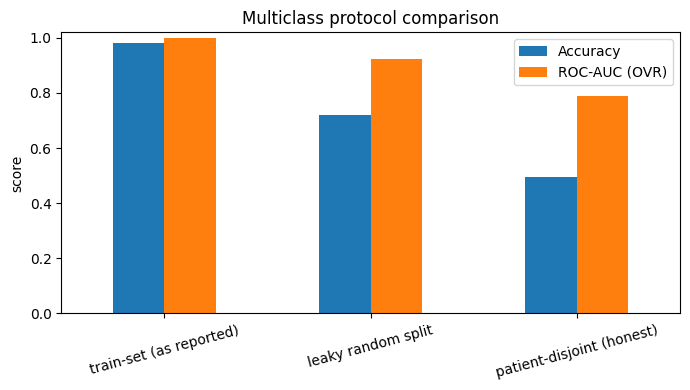

In [11]:
ax = comparison.T[["acc", "auc"]].plot(kind="bar", figsize=(7, 4), rot=15, ylim=(0.0, 1.02))
ax.set_ylabel("score")
ax.set_title("Multiclass protocol comparison")
ax.legend(["Accuracy", "ROC-AUC (OVR)"])
plt.tight_layout()
plt.savefig(OUT / "fig_protocol_gap_multiclass.png", dpi=150)
plt.show()

The difference between these bars is the correction that belongs in the
progress report. It is not a failure of the model — it is the difference
between measuring fit and measuring generalisation.

## 9. Permutation sanity check on the baseline

The conditional-fusion model is permutation-invariant over magnifications by
construction, so shuffling the scale order at test time should change nothing
beyond the magnification embedding. Confirming that here establishes the
reference point that notebook 03 compares ZoomMoE against: if ZoomMoE is
genuinely modelling zoom as a process, its permuted score should drop and the
baseline's should not.

In [12]:
@torch.no_grad()
def permuted_score(model, samples, idx, n_perm=5):
    loader = DataLoader(
        bc.make_feature_dataset(samples.iloc[idx], feat_cache), batch_size=64, num_workers=2
    )
    model.eval()
    scores = []
    for t in range(n_perm):
        g = torch.Generator().manual_seed(SEED + t)
        probs, ys, pids = [], [], []
        for batch in loader:
            feats = batch["feats"].to(DEVICE)
            mask = batch["mask"].to(DEVICE)
            perm = torch.randperm(feats.shape[1], generator=g)
            logits = model(feats[:, perm], mask[:, perm])
            probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
            ys.append(batch["label"].numpy())
            pids.append(batch["patient_idx"].numpy())
        scores.append(bc.evaluate(np.concatenate(ys), np.concatenate(probs), np.concatenate(pids)))
    return pd.DataFrame(scores).mean()


bc.set_seed(SEED)
fold0 = folds_full[0]
ds_tr = bc.make_feature_dataset(samples_full.iloc[fold0["train"]], feat_cache)
ldr = DataLoader(ds_tr, batch_size=64, shuffle=True, num_workers=2)
ref = ConditionalFusion().to(DEVICE)
opt = torch.optim.Adam(ref.parameters(), lr=1e-3)
for _ in range(EPOCHS):
    run_epoch(ref, ldr, opt)

_, p0, y0, pid0 = run_epoch(
    ref, DataLoader(bc.make_feature_dataset(samples_full.iloc[fold0["test"]], feat_cache), batch_size=64)
)
print("ordered   :", {k: round(v, 4) for k, v in bc.evaluate(y0, p0, pid0).items()})
print("permuted  :", permuted_score(ref, samples_full, fold0["test"]).round(4).to_dict())
torch.save(ref.state_dict(), OUT / "baseline_fusion_multiclass_fold0.pt")

ordered   : {'acc': 0.4275, 'f1_macro': 0.3426, 'prr': 0.4219, 'auc': 0.8102}
permuted  : {'acc': 0.4497, 'f1_macro': 0.3551, 'prr': 0.4464, 'auc': 0.8233}


## 10. Handoff

Written to `artifacts/`:

| file | used by |
|---|---|
| `samples_all.pkl`, `samples_pool.pkl`, `samples_full.pkl` | 02, 03 |
| `folds_all.npy`, `folds_full.npy` | 02, 03 |
| `vgg16_features.npz` | 03 (t-SNE "before fusion") |
| `baseline_results_honest.csv`, `protocol_comparison.csv` | the report |
| `baseline_fusion_fold0.pt` | 03 (comparison curves) |

Next: `02_zoommoe_train.ipynb`.